# 10 – Baseline: ConvNeXt-Tiny, 5 folds

The **first model that goes all the way**: training → evaluation on the two shared validations → prediction of the test set → `submission.csv`. Every later experiment is compared with this one, changing **one thing at a time**.

| choice | value | why |
|---|---|---|
| data | the 2,995 clean images, shared folds (`folds.csv`) | same split as the whole team |
| model | **ConvNeXt-Tiny**, ImageNet pretrained (`timm`) | strong general-purpose CNN, allowed by the rules |
| resolution | **256×256** (native) | no loss of fine detail (bars, spiral arms) |
| augmentation | **only the 8 symmetries** of the square (flips + 90° rotations) | a galaxy keeps its class when rotated/flipped; **no colour / blur on purpose**, to measure the damage of the test shift |
| loss | cross-entropy + **label smoothing 0.1** | some labels are noisy, some classes are ambiguous |
| optimiser | AdamW, lr 2e-4, weight decay 0.05, 1-epoch warmup + cosine, 20 epochs, batch 64 | standard fine-tuning recipe for ConvNeXt |
| evaluation | weighted F1 on the **clean** and **shifted** validation, 8-view TTA | shared protocol (`common.py`) |
| submission | mean of the 5 fold models × 8 TTA views | more robust than a single model |

Run order: fold 0 first (a **check**: look at its curves before trusting the rest), then folds 1–4, then the test prediction. Details and motivations: note *FASE 2 – Baseline*.

Runs on the PC (repo: `families/elia/`, imports `common.py` from `eda/elia/`) and on Kaggle (inputs: `an2dl2627-data` + `batchsize4-shared-split`, **Internet on** to download the pretrained weights, GPU accelerator).

## 0. Setup and configuration

In [2]:
import sys, os, glob, json, time, math, random
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

# --- find common.py: repo (eda/elia), Mac working copy (elia_pc) or a Kaggle input ---------------
_cands = [Path.cwd().parent.parent / "eda" / "elia", Path.cwd().parent.parent / "elia_pc"]
_cands += [Path(p).parent for p in glob.glob("/kaggle/input/**/common.py", recursive=True)]
COMMON_DIR = next(p for p in _cands if (p / "common.py").exists())
sys.path.insert(0, str(COMMON_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
import timm.optim
from sklearn.metrics import ConfusionMatrixDisplay

import common as C

plt.rcParams["figure.dpi"] = 80
print("common.py from:", COMMON_DIR)
print("DATA:", C.DATA)

common.py from: /home/elia/ANN-DL-Challenge/eda/elia
DATA: /home/elia/ANN-DL-Challenge/data


In [3]:
CFG = dict(
    run_name="baseline_convnext_tiny_256",
    model="convnext_tiny.fb_in22k_ft_in1k",   # ImageNet (22k -> 1k) pretrained, general purpose
    img_size=256,
    epochs=20,
    batch_size=64,
    lr=2e-4,
    weight_decay=0.05,
    warmup_epochs=1,
    label_smoothing=0.1,
    drop_path=0.1,
    folds=[0, 1, 2, 3, 4],
    seed=42,
    tta=True,
    smoke_test=False,     # True = tiny quick run to check that the code works (few images, 1 epoch)
)
if CFG["smoke_test"]:
    CFG.update(epochs=1, folds=[0], batch_size=16)

DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"                    # bf16 mixed precision on the NVIDIA GPU

# where to write: next to this notebook if possible, otherwise the Kaggle working directory
_base = Path.cwd() if os.access(Path.cwd(), os.W_OK) and not Path("/kaggle/working").exists() else Path("/kaggle/working")
RUN_DIR = _base / "outputs" / CFG["run_name"]
RUN_DIR.mkdir(parents=True, exist_ok=True)
LOG_FILE = _base / "experiments_log.csv"
(RUN_DIR / "config.json").write_text(json.dumps(CFG, indent=2))

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything(CFG["seed"])
torch.backends.cudnn.benchmark = True
print("device:", DEVICE, "| mixed precision:", USE_AMP, "| outputs:", RUN_DIR)

device: cuda | mixed precision: True | outputs: /home/elia/ANN-DL-Challenge/families/elia/outputs/baseline_convnext_tiny_256


## 1. Data

- `folds.csv`: the 2,995 clean images with their fold; `val_shift_plan.csv`: the fixed alteration of each validation image.
- All training images are loaded **into memory once** as a `uint8` array (2,995 × 256 × 256 × 3 ≈ 590 MB): every epoch then reads from RAM, which is much faster than reading PNG files.
- The **shifted** version of every image is also built once from the plan (`C.load_shifted`): it is used only for validation.
- The test images are loaded later, only for the final prediction.

In [4]:
folds = pd.read_csv(C.SPLITS / "folds.csv")
plan = pd.read_csv(C.SPLITS / "val_shift_plan.csv").set_index("id")
test_ids = pd.read_csv(C.DATA / "sample_submission.csv").id.tolist()
if CFG["smoke_test"]:
    folds = folds.groupby("fold").head(60).reset_index(drop=True)   # 60 images per fold
    test_ids = test_ids[:64]

def load_many(ids, loader):
    with ThreadPoolExecutor(8) as ex:
        return np.stack(list(ex.map(lambda i: np.asarray(loader(i)), ids)))

t0 = time.time()
X_clean = load_many(folds.id, C.load_image)                              # (N, 256, 256, 3) uint8
X_shift = load_many(folds.id, lambda i: C.load_shifted(i, plan))
y_all = folds.label.to_numpy()
print(f"loaded {len(X_clean)} images (+ shifted versions) in {time.time() - t0:.0f}s, "
      f"{X_clean.nbytes / 1e9:.2f} GB each")

loaded 2995 images (+ shifted versions) in 6s, 0.59 GB each


## 2. Model, augmentation and helpers

- **Model:** `timm.create_model(..., pretrained=True, num_classes=10)` loads ConvNeXt-Tiny with the ImageNet weights and replaces the last layer (1,000 ImageNet classes) with a new one with **10 outputs**. The whole network is fine-tuned. `drop_path_rate` randomly skips some blocks during training (regularisation).
- **Normalisation:** pixels in [0, 1], then the ImageNet mean / std per channel, as during pre-training.
- **Augmentation (training only):** each image gets one of the **8 symmetries** of the square (0/90/180/270° rotation, optionally flipped). It is applied on the GPU, on whole batches.
- **TTA (evaluation):** each image is predicted in all 8 symmetries and the probabilities are averaged.

In [5]:
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

def to_input(x_uint8):
    # (B, H, W, 3) uint8 numpy/tensor -> normalised (B, 3, H, W) float tensor on the device
    x = torch.as_tensor(x_uint8, device=DEVICE).permute(0, 3, 1, 2).float() / 255.0
    if x.shape[-1] != CFG["img_size"]:
        x = F.interpolate(x, size=CFG["img_size"], mode="bilinear", antialias=True, align_corners=False)
    return (x - MEAN) / STD

def dihedral(x, k):
    # symmetry k in 0..7 of a (B, C, H, W) batch: rotation by k % 4 quarter turns, flipped if k >= 4
    x = torch.rot90(x, k % 4, dims=(2, 3))
    return torch.flip(x, dims=(3,)) if k >= 4 else x

def random_dihedral(x):
    # a different random symmetry for every image of the batch
    ks = torch.randint(0, 8, (x.shape[0],), device=x.device)
    out = torch.empty_like(x)
    for k in range(8):
        m = ks == k
        if m.any():
            out[m] = dihedral(x[m], k)
    return out

def make_model():
    return timm.create_model(CFG["model"], pretrained=True, num_classes=C.N_CLASSES,
                             drop_path_rate=CFG["drop_path"]).to(DEVICE)

@torch.no_grad()
def predict_proba(model, X, tta=True, batch_size=128):
    # class probabilities (N, 10) for uint8 images X; with TTA: mean over the 8 symmetries
    model.eval()
    out = []
    for i in range(0, len(X), batch_size):
        x = to_input(X[i:i + batch_size])
        views = range(8) if tta else [0]
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=USE_AMP):
            p = sum(F.softmax(model(dihedral(x, k)).float(), dim=1) for k in views) / len(views)
        out.append(p.cpu().numpy())
    return np.concatenate(out)

def make_scheduler(optimizer, steps_per_epoch):
    # linear warmup for warmup_epochs, then cosine decay to ~0 (computed per optimisation step)
    total = CFG["epochs"] * steps_per_epoch
    warm = CFG["warmup_epochs"] * steps_per_epoch
    def factor(step):
        if step < warm:
            return (step + 1) / warm
        return 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, total - warm)))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, factor)

## 3. Training one fold

For fold *k*:
1. training images = folds ≠ *k*; validation images = fold *k* (clean and shifted);
2. at every epoch: one pass over the shuffled training images with random symmetries, then the weighted F1 on both validations (without TTA, to keep it fast);
3. at the end: the model of the **last epoch** is kept (choosing the best epoch on the validation would make the score slightly optimistic), and evaluated **with TTA**; its validation probabilities are stored as out-of-fold predictions.

In [6]:
def train_fold(k):
    seed_everything(CFG["seed"] + k)
    tr_idx = np.where(folds.fold.to_numpy() != k)[0]
    va_idx = np.where(folds.fold.to_numpy() == k)[0]
    model = make_model()
    optimizer = timm.optim.create_optimizer_v2(model, "adamw", lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    steps = math.ceil(len(tr_idx) / CFG["batch_size"])
    scheduler = make_scheduler(optimizer, steps)
    criterion = nn.CrossEntropyLoss(label_smoothing=CFG["label_smoothing"])
    y_va = y_all[va_idx]

    history = []
    for epoch in range(CFG["epochs"]):
        model.train()
        t0, losses = time.time(), []
        perm = np.random.permutation(tr_idx)
        for i in range(0, len(perm), CFG["batch_size"]):
            b = perm[i:i + CFG["batch_size"]]
            x = random_dihedral(to_input(X_clean[b]))
            y = torch.as_tensor(y_all[b], device=DEVICE)
            with torch.autocast("cuda", dtype=torch.bfloat16, enabled=USE_AMP):
                loss = criterion(model(x), y)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            scheduler.step()
            losses.append(loss.item())
        p_clean = predict_proba(model, X_clean[va_idx], tta=False)
        p_shift = predict_proba(model, X_shift[va_idx], tta=False)
        history.append({"epoch": epoch + 1, "train_loss": np.mean(losses),
                        "val_loss_clean": F.nll_loss(torch.log(torch.tensor(p_clean) + 1e-8), torch.tensor(y_va)).item(),
                        "val_loss_shifted": F.nll_loss(torch.log(torch.tensor(p_shift) + 1e-8), torch.tensor(y_va)).item(),
                        "f1_clean": C.evaluate(y_va, p_clean.argmax(1))["f1_weighted"],
                        "f1_shifted": C.evaluate(y_va, p_shift.argmax(1))["f1_weighted"],
                        "seconds": time.time() - t0})
        h = history[-1]
        print(f"fold {k} | epoch {h['epoch']:2d} | train loss {h['train_loss']:.3f} | "
              f"F1 clean {h['f1_clean']:.3f} | F1 shifted {h['f1_shifted']:.3f} | {h['seconds']:.0f}s")

    torch.save(model.state_dict(), RUN_DIR / f"model_fold{k}.pt")
    p_clean = predict_proba(model, X_clean[va_idx], tta=CFG["tta"])
    p_shift = predict_proba(model, X_shift[va_idx], tta=CFG["tta"])
    return model, pd.DataFrame(history), va_idx, p_clean, p_shift


def plot_history(hist, k):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    axes[0].plot(hist.epoch, hist.train_loss, label="train")
    axes[0].plot(hist.epoch, hist.val_loss_clean, label="val clean")
    axes[0].plot(hist.epoch, hist.val_loss_shifted, label="val shifted")
    axes[0].set_title(f"fold {k}: loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
    axes[1].plot(hist.epoch, hist.f1_clean, label="val clean")
    axes[1].plot(hist.epoch, hist.f1_shifted, label="val shifted")
    axes[1].set_title(f"fold {k}: weighted F1"); axes[1].set_xlabel("epoch"); axes[1].legend()
    plt.tight_layout(); plt.show()


# containers filled fold by fold
oof_clean = np.zeros((len(folds), C.N_CLASSES), np.float32)
oof_shift = np.zeros((len(folds), C.N_CLASSES), np.float32)
fold_results, histories, models = [], {}, {}

def run_fold(k):
    t0 = time.time()
    model, hist, va_idx, p_clean, p_shift = train_fold(k)
    oof_clean[va_idx], oof_shift[va_idx] = p_clean, p_shift
    res_c, res_s = C.evaluate(y_all[va_idx], p_clean.argmax(1)), C.evaluate(y_all[va_idx], p_shift.argmax(1))
    fold_results.append({"fold": k, **C.summary_row(CFG["run_name"], res_c, res_s), "minutes": (time.time() - t0) / 60})
    histories[k], models[k] = hist, model
    print(f"\nfold {k} with TTA: F1 clean {res_c['f1_weighted']:.4f} | F1 shifted {res_s['f1_weighted']:.4f} "
          f"| {(time.time() - t0) / 60:.1f} min")
    plot_history(hist, k)

## 4. Fold 0 – check before going on

**What to look at:**
- the training loss goes down steadily;
- the validation F1 goes up and then stabilises; it should be clearly above the frozen linear probe (≈ 0.62);
- the **shifted** curve is below the clean one: the gap is the damage of the test shift that the next phase will try to reduce;
- if the validation loss rises a lot while the training loss keeps falling → overfitting.

If something looks wrong, stop here instead of running the other folds.

fold 0 | epoch  1 | train loss 2.042 | F1 clean 0.346 | F1 shifted 0.317 | 50s
fold 0 | epoch  2 | train loss 1.494 | F1 clean 0.720 | F1 shifted 0.700 | 4s
fold 0 | epoch  3 | train loss 1.186 | F1 clean 0.769 | F1 shifted 0.742 | 4s
fold 0 | epoch  4 | train loss 1.073 | F1 clean 0.801 | F1 shifted 0.772 | 4s
fold 0 | epoch  5 | train loss 0.986 | F1 clean 0.783 | F1 shifted 0.765 | 4s
fold 0 | epoch  6 | train loss 0.957 | F1 clean 0.817 | F1 shifted 0.800 | 4s
fold 0 | epoch  7 | train loss 0.883 | F1 clean 0.808 | F1 shifted 0.792 | 4s
fold 0 | epoch  8 | train loss 0.857 | F1 clean 0.836 | F1 shifted 0.827 | 4s
fold 0 | epoch  9 | train loss 0.798 | F1 clean 0.844 | F1 shifted 0.824 | 4s
fold 0 | epoch 10 | train loss 0.771 | F1 clean 0.827 | F1 shifted 0.818 | 4s
fold 0 | epoch 11 | train loss 0.754 | F1 clean 0.825 | F1 shifted 0.806 | 4s
fold 0 | epoch 12 | train loss 0.707 | F1 clean 0.838 | F1 shifted 0.827 | 4s
fold 0 | epoch 13 | train loss 0.692 | F1 clean 0.845 | F1 shif

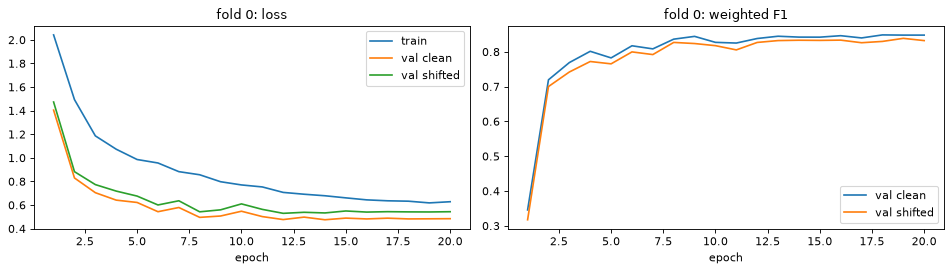

In [7]:
run_fold(CFG["folds"][0])

Considerations:
- F1 score grows up to the 10th-12th epoch and then reaches a plateau until epoch 20.
- Validation does not get worse towards the end $\implies$ no overfitting

Therefore:
- 20 epochs are enough and do not cause trouble.

Let's see also the curves of the other folds to confirm n_epochs = 20.

## 5. Folds 1–4

fold 1 | epoch  1 | train loss 1.973 | F1 clean 0.454 | F1 shifted 0.436 | 4s
fold 1 | epoch  2 | train loss 1.401 | F1 clean 0.731 | F1 shifted 0.677 | 4s
fold 1 | epoch  3 | train loss 1.164 | F1 clean 0.758 | F1 shifted 0.725 | 4s
fold 1 | epoch  4 | train loss 1.032 | F1 clean 0.789 | F1 shifted 0.742 | 4s
fold 1 | epoch  5 | train loss 0.981 | F1 clean 0.800 | F1 shifted 0.763 | 4s
fold 1 | epoch  6 | train loss 0.917 | F1 clean 0.804 | F1 shifted 0.765 | 4s
fold 1 | epoch  7 | train loss 0.879 | F1 clean 0.805 | F1 shifted 0.767 | 4s
fold 1 | epoch  8 | train loss 0.809 | F1 clean 0.793 | F1 shifted 0.754 | 4s
fold 1 | epoch  9 | train loss 0.793 | F1 clean 0.796 | F1 shifted 0.770 | 4s
fold 1 | epoch 10 | train loss 0.765 | F1 clean 0.806 | F1 shifted 0.769 | 4s
fold 1 | epoch 11 | train loss 0.748 | F1 clean 0.807 | F1 shifted 0.778 | 4s
fold 1 | epoch 12 | train loss 0.705 | F1 clean 0.823 | F1 shifted 0.778 | 4s
fold 1 | epoch 13 | train loss 0.690 | F1 clean 0.833 | F1 shift

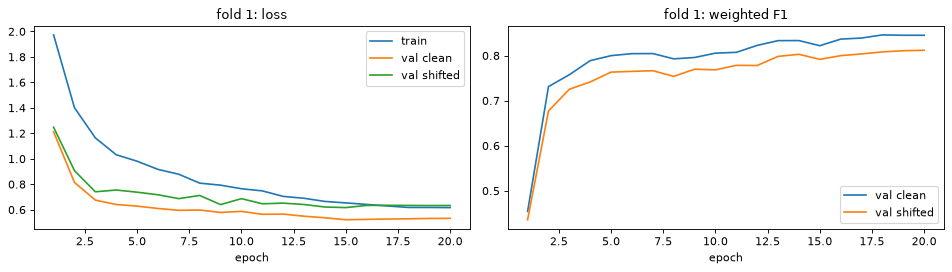

fold 2 | epoch  1 | train loss 2.056 | F1 clean 0.599 | F1 shifted 0.587 | 4s
fold 2 | epoch  2 | train loss 1.423 | F1 clean 0.717 | F1 shifted 0.687 | 4s
fold 2 | epoch  3 | train loss 1.164 | F1 clean 0.762 | F1 shifted 0.754 | 4s
fold 2 | epoch  4 | train loss 1.046 | F1 clean 0.772 | F1 shifted 0.764 | 4s
fold 2 | epoch  5 | train loss 0.968 | F1 clean 0.799 | F1 shifted 0.798 | 4s
fold 2 | epoch  6 | train loss 0.902 | F1 clean 0.773 | F1 shifted 0.754 | 4s
fold 2 | epoch  7 | train loss 0.846 | F1 clean 0.790 | F1 shifted 0.780 | 4s
fold 2 | epoch  8 | train loss 0.804 | F1 clean 0.816 | F1 shifted 0.810 | 4s
fold 2 | epoch  9 | train loss 0.771 | F1 clean 0.811 | F1 shifted 0.805 | 4s
fold 2 | epoch 10 | train loss 0.739 | F1 clean 0.823 | F1 shifted 0.812 | 4s
fold 2 | epoch 11 | train loss 0.714 | F1 clean 0.816 | F1 shifted 0.809 | 4s
fold 2 | epoch 12 | train loss 0.692 | F1 clean 0.823 | F1 shifted 0.804 | 4s
fold 2 | epoch 13 | train loss 0.675 | F1 clean 0.818 | F1 shift

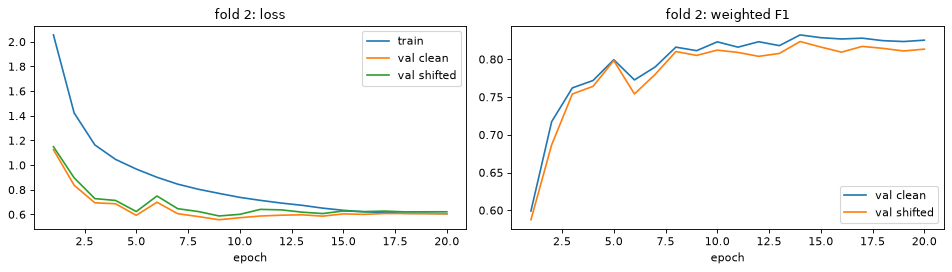

fold 3 | epoch  1 | train loss 2.005 | F1 clean 0.556 | F1 shifted 0.539 | 4s
fold 3 | epoch  2 | train loss 1.380 | F1 clean 0.727 | F1 shifted 0.707 | 4s
fold 3 | epoch  3 | train loss 1.119 | F1 clean 0.779 | F1 shifted 0.755 | 4s
fold 3 | epoch  4 | train loss 1.020 | F1 clean 0.759 | F1 shifted 0.727 | 4s
fold 3 | epoch  5 | train loss 0.952 | F1 clean 0.784 | F1 shifted 0.760 | 4s
fold 3 | epoch  6 | train loss 0.890 | F1 clean 0.808 | F1 shifted 0.792 | 4s
fold 3 | epoch  7 | train loss 0.870 | F1 clean 0.808 | F1 shifted 0.788 | 4s
fold 3 | epoch  8 | train loss 0.822 | F1 clean 0.806 | F1 shifted 0.802 | 4s
fold 3 | epoch  9 | train loss 0.785 | F1 clean 0.809 | F1 shifted 0.801 | 4s
fold 3 | epoch 10 | train loss 0.763 | F1 clean 0.829 | F1 shifted 0.823 | 4s
fold 3 | epoch 11 | train loss 0.728 | F1 clean 0.825 | F1 shifted 0.820 | 4s
fold 3 | epoch 12 | train loss 0.694 | F1 clean 0.834 | F1 shifted 0.825 | 4s
fold 3 | epoch 13 | train loss 0.672 | F1 clean 0.829 | F1 shift

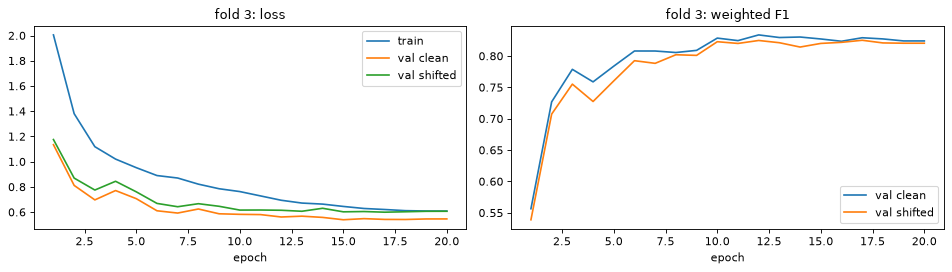

fold 4 | epoch  1 | train loss 2.073 | F1 clean 0.405 | F1 shifted 0.391 | 4s
fold 4 | epoch  2 | train loss 1.480 | F1 clean 0.718 | F1 shifted 0.686 | 4s
fold 4 | epoch  3 | train loss 1.203 | F1 clean 0.727 | F1 shifted 0.699 | 4s
fold 4 | epoch  4 | train loss 1.055 | F1 clean 0.769 | F1 shifted 0.719 | 4s
fold 4 | epoch  5 | train loss 0.979 | F1 clean 0.766 | F1 shifted 0.723 | 4s
fold 4 | epoch  6 | train loss 0.928 | F1 clean 0.808 | F1 shifted 0.775 | 4s
fold 4 | epoch  7 | train loss 0.883 | F1 clean 0.811 | F1 shifted 0.776 | 4s
fold 4 | epoch  8 | train loss 0.831 | F1 clean 0.821 | F1 shifted 0.785 | 4s
fold 4 | epoch  9 | train loss 0.802 | F1 clean 0.812 | F1 shifted 0.767 | 4s
fold 4 | epoch 10 | train loss 0.767 | F1 clean 0.810 | F1 shifted 0.783 | 4s
fold 4 | epoch 11 | train loss 0.739 | F1 clean 0.837 | F1 shifted 0.802 | 4s
fold 4 | epoch 12 | train loss 0.704 | F1 clean 0.825 | F1 shifted 0.796 | 4s
fold 4 | epoch 13 | train loss 0.691 | F1 clean 0.828 | F1 shift

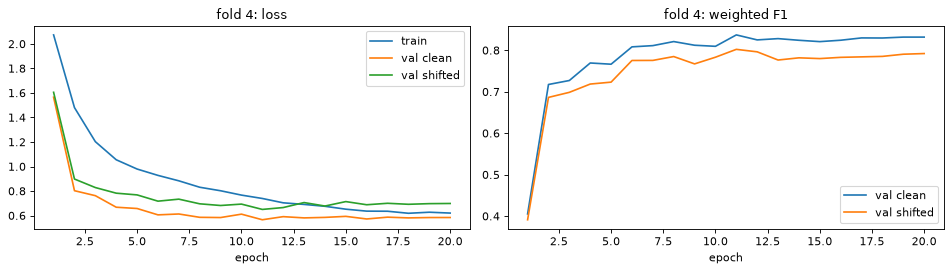

In [8]:
for k in CFG["folds"][1:]:
    run_fold(k)

## 6. Cross-validation results

- **Per fold:** weighted F1 on the clean and shifted validation (with TTA).
- **Mean ± std** over the folds: the std tells how much a single fold can be trusted.
- **Out-of-fold (OOF):** every image was predicted by the model that did not see it, so the F1 on all 2,995 images is the most stable estimate.

In [9]:
res = pd.DataFrame(fold_results)
display(res.round(4))
print(f"weighted F1 clean  : {res.f1_clean.mean():.4f} ± {res.f1_clean.std():.4f}")
print(f"weighted F1 shifted: {res.f1_shifted.mean():.4f} ± {res.f1_shifted.std():.4f}")

done = folds.fold.isin(CFG["folds"]).to_numpy()
oof_res_clean = C.evaluate(y_all[done], oof_clean[done].argmax(1))
oof_res_shift = C.evaluate(y_all[done], oof_shift[done].argmax(1))
print(f"\nOOF F1 on {done.sum()} images: clean {oof_res_clean['f1_weighted']:.4f} | shifted {oof_res_shift['f1_weighted']:.4f}")
pd.DataFrame({"clean": oof_res_clean["f1_per_class"], "shifted": oof_res_shift["f1_per_class"]}).round(3)

,fold,experiment,f1_clean,f1_shifted,f1_cigar_clean,f1_cigar_shifted,minutes
0,0,baseline_convnext_tiny_256,0.8514,0.8307,0.7500,0.6667,2.2671
1,1,baseline_convnext_tiny_256,0.8514,0.8164,0.7619,0.7500,1.5015
2,2,baseline_convnext_tiny_256,0.8440,0.8300,0.8333,0.7692,1.5033
3,3,baseline_convnext_tiny_256,0.8281,0.8242,0.8000,0.6897,1.5004
4,4,baseline_convnext_tiny_256,0.8420,0.7982,0.6957,0.6400,1.5051


weighted F1 clean  : 0.8434 ± 0.0095
weighted F1 shifted: 0.8199 ± 0.0134

OOF F1 on 2995 images: clean 0.8435 | shifted 0.8200


,clean,shifted
0 disturbed,0.474,0.419
1 merging,0.899,0.886
2 round smooth,0.930,0.926
3 in-between smooth,0.916,0.908
4 cigar,0.769,0.703
5 barred spiral,0.863,0.838
6 tight spiral,0.774,0.736
7 loose spiral,0.747,0.712
8 edge-on no bulge,0.918,0.901
9 edge-on bulge,0.939,0.916


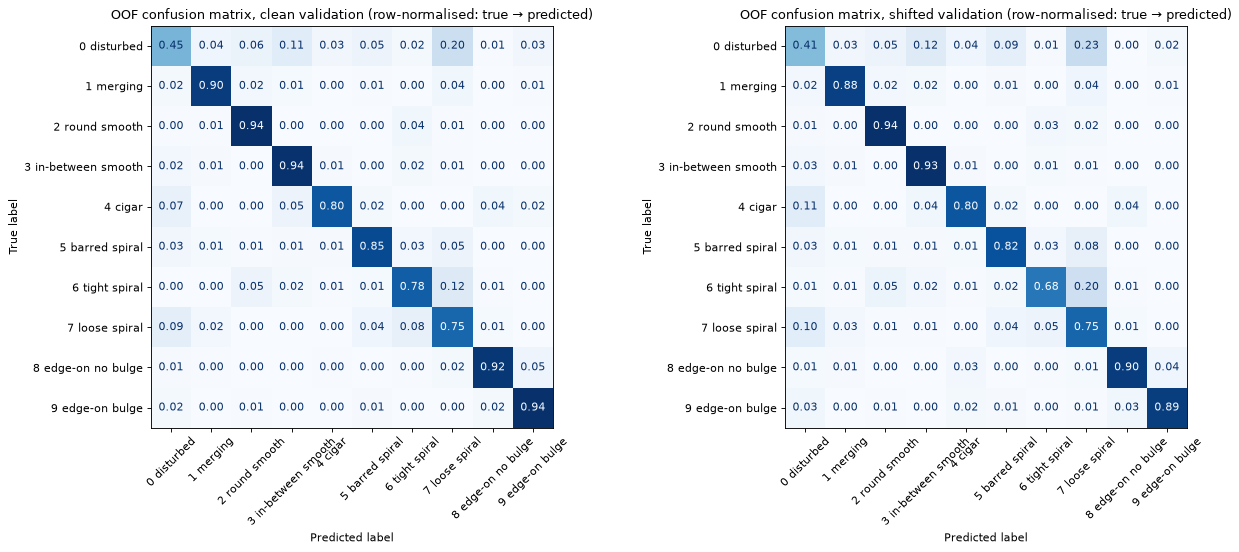

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
labels = [f"{c} {C.CLASSES[c]}" for c in range(C.N_CLASSES)]
for ax, res_, title in [(axes[0], oof_res_clean, "clean"), (axes[1], oof_res_shift, "shifted")]:
    cm = res_["confusion"] / res_["confusion"].sum(1, keepdims=True).clip(min=1)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, values_format=".2f", cmap="Blues",
                                                           colorbar=False, xticks_rotation=45)
    ax.set_title(f"OOF confusion matrix, {title} validation (row-normalised: true → predicted)")
plt.tight_layout(); plt.show()

In [11]:
# save the out-of-fold probabilities (used for error analysis and, later, for ensembling with other models)
oof = pd.DataFrame({"id": folds.id, "label": y_all, "fold": folds.fold})
for name, P in [("clean", oof_clean), ("shifted", oof_shift)]:
    for c in range(C.N_CLASSES):
        oof[f"p{c}_{name}"] = P[:, c]
oof.to_csv(RUN_DIR / "oof.csv", index=False)
print("saved", RUN_DIR / "oof.csv")

saved /home/elia/ANN-DL-Challenge/families/elia/outputs/baseline_convnext_tiny_256/oof.csv


## 7. Test prediction and submission

- The 14,736 test images are loaded once.
- Each of the 5 fold models predicts them with 8-view TTA; the probabilities are **averaged over the models**.
- The class with the highest mean probability is written to `submission.csv` (`id,label`, same order as `sample_submission.csv`).
- The per-model probabilities are also saved (`test_probs.npy`), for future ensembles.

In [12]:
t0 = time.time()
X_test = load_many(test_ids, C.load_image)
print(f"loaded {len(X_test)} test images in {time.time() - t0:.0f}s")

test_probs = np.stack([predict_proba(models[k], X_test, tta=CFG["tta"]) for k in CFG["folds"]])   # (folds, N, 10)
np.save(RUN_DIR / "test_probs.npy", test_probs)
p_mean = test_probs.mean(0)

sub = pd.DataFrame({"id": test_ids, "label": p_mean.argmax(1)})
sub_file = RUN_DIR / ("submission_SMOKE_TEST.csv" if CFG["smoke_test"] else "submission.csv")
sub.to_csv(sub_file, index=False)
print("saved", sub_file)
print("predicted class distribution on the test (%):")
print((100 * sub.label.value_counts(normalize=True).sort_index()).round(1).rename(index=C.CLASSES).to_string())

loaded 14736 test images in 15s
saved /home/elia/ANN-DL-Challenge/families/elia/outputs/baseline_convnext_tiny_256/submission.csv
predicted class distribution on the test (%):
label
disturbed             5.4
merging              10.3
round smooth         15.2
in-between smooth    12.1
cigar                 2.5
barred spiral        11.2
tight spiral          8.7
loose spiral         16.4
edge-on no bulge      8.0
edge-on bulge        10.3


**Sanity check of the predicted class distribution.** It should be roughly similar to the class proportions of the training set (largest classes 2, 3, 5, 6, 7; class 4 around 2%). A class that is almost never or far too often predicted is a warning sign.

## 8. Experiment log
One row per fold plus one row for the out-of-fold result, appended to `experiments_log.csv`. After the Kaggle submission, write its public score in the `kaggle` column of the OOF row.

In [13]:
rows = [{"date": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"), "train_set": "clean (keep=True)", "kaggle": None,
         "note": "baseline: dihedral aug only, label smoothing 0.1", **r} for r in fold_results]
rows.append({"date": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"), "fold": "OOF", "train_set": "clean (keep=True)",
             **C.summary_row(CFG["run_name"], oof_res_clean, oof_res_shift), "kaggle": None,
             "note": "baseline: 5-fold out-of-fold, TTA"})
if not CFG["smoke_test"]:
    log = pd.concat([pd.read_csv(LOG_FILE), pd.DataFrame(rows)]) if LOG_FILE.exists() else pd.DataFrame(rows)
    log.to_csv(LOG_FILE, index=False)
pd.DataFrame(rows).round(4)

,date,train_set,kaggle,note,fold,experiment,f1_clean,f1_shifted,f1_cigar_clean,f1_cigar_shifted,minutes
0,2026-11-27 15:54,clean (keep=True),None,"baseline: dihedral aug only, label smoothing 0.1",0,baseline_convnext_tiny_256,0.8514,0.8307,0.7500,0.6667,2.2671
1,2026-11-27 15:54,clean (keep=True),None,"baseline: dihedral aug only, label smoothing 0.1",1,baseline_convnext_tiny_256,0.8514,0.8164,0.7619,0.7500,1.5015
2,2026-11-27 15:54,clean (keep=True),None,"baseline: dihedral aug only, label smoothing 0.1",2,baseline_convnext_tiny_256,0.8440,0.8300,0.8333,0.7692,1.5033
3,2026-11-27 15:54,clean (keep=True),None,"baseline: dihedral aug only, label smoothing 0.1",3,baseline_convnext_tiny_256,0.8281,0.8242,0.8000,0.6897,1.5004
4,2026-11-27 15:54,clean (keep=True),None,"baseline: dihedral aug only, label smoothing 0.1",4,baseline_convnext_tiny_256,0.8420,0.7982,0.6957,0.6400,1.5051
5,2026-11-27 15:54,clean (keep=True),None,"baseline: 5-fold out-of-fold, TTA",OOF,baseline_convnext_tiny_256,0.8435,0.8200,0.7692,0.7031,NaN


## 9. How many epochs are needed?

Mean weighted F1 per epoch over the 5 folds (validation without TTA), on the clean and on the shifted validation.

**Why:** the number of epochs (20) was chosen a priori. Instead of early stopping inside each training run, which would make the validation score optimistic, would be dominated by the epoch-to-epoch noise of a 599-image fold, and would be ambiguous with two validations, we choose the number of epochs **once, at the experiment level**, by looking at where the **average** curve of the 5 folds stops improving.

**How to read it:**
- if the curves are flat over the last epochs, the model has converged: 20 epochs are enough, and fewer would give about the same result;
- if they are still rising at epoch 20, more epochs could help;
- if they go down at the end, the model is overfitting and fewer epochs (or more regularisation) are needed.

With the cosine schedule the learning rate reaches ~0 at the last epoch, so the last epochs fine-tune the weights with very small steps: this is why the model of the last epoch is kept.

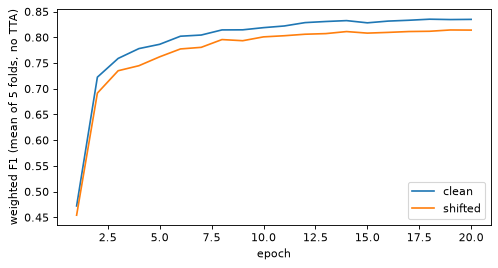

f1_clean        f1_shifted       
          mean    std       mean    std
epoch                                  
1        0.472  0.105      0.454  0.109
2        0.723  0.006      0.692  0.012
3        0.759  0.019      0.735  0.024
4        0.778  0.017      0.745  0.023
5        0.786  0.014      0.762  0.027
6        0.802  0.017      0.777  0.019
7        0.804  0.009      0.781  0.010
8        0.814  0.016      0.796  0.028
9        0.815  0.018      0.793  0.024
10       0.819  0.011      0.801  0.024
11       0.822  0.011      0.803  0.015
12       0.829  0.007      0.806  0.020
13       0.831  0.010      0.807  0.021
14       0.832  0.007      0.811  0.020
15       0.828  0.008      0.808  0.022
16       0.832  0.010      0.810  0.020
17       0.833  0.006      0.811  0.018
18       0.835  0.011      0.812  0.017
19       0.834  0.012      0.814  0.017
20       0.835  0.011      0.814  0.015

In [14]:
h = pd.concat(histories.values()).groupby("epoch")[["f1_clean", "f1_shifted"]].agg(["mean", "std"])
ax = h[("f1_clean", "mean")].plot(label="clean", figsize=(7, 3.5))
h[("f1_shifted", "mean")].plot(ax=ax, label="shifted")
ax.set_xlabel("epoch"); ax.set_ylabel("weighted F1 (mean of 5 folds, no TTA)"); ax.legend(); plt.show()
h.round(3)

## Summary

Fill in after the run:
- **CV weighted F1:** clean ___ ± ___ | shifted ___ ± ___ | OOF clean ___ | OOF shifted ___
- **Gap clean − shifted:** ___ → the damage of the test shift without colour/blur augmentation
- **Kaggle public score:** ___ → compare with the shifted OOF F1: if close, our shifted validation is a good proxy of the test
- **Weakest classes:** ___

**Next (phase 3):** add, one at a time, hue rotation, mild blur, brightness/noise augmentation, and compare each run with this baseline on the shifted validation.